### Car Price Prediction Project

#### Objective : The goal of this project is to build a machine learning model that predicts the selling price of cars based on their features 

#### Problem Statement : Used car dealerships and buyers want to estimate the correct resale value of cars. An accurate price prediction system can help both sellers and buyers make better decisions. In this project, you are required to use data preprocessing, exploratory data analysis, and regression modeling to predict car prices.

### Step 1: Data Gathering And understanding

In [1]:
import pandas as pd 
path = r"C:\Users\Sakshi\Downloads\Cars93.csv"
df = pd.read_csv(path)
df.head()

,id,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,1,Acura,Integra,Small,12.9,15.9,18.8,25,31,NaN,...,5,177,102,68,37,26.5,11.0,2705,non-USA,Acura Integra
1,2,Acura,Legend,Midsize,29.2,33.9,38.7,18,25,Driver & Passenger,...,5,195,115,71,38,30.0,15.0,3560,non-USA,Acura Legend
2,3,Audi,90,Compact,25.9,29.1,32.3,20,26,Driver only,...,5,180,102,67,37,28.0,14.0,3375,non-USA,Audi 90
3,4,Audi,100,Midsize,30.8,37.7,44.6,19,26,NaN,...,6,193,106,70,37,31.0,17.0,3405,non-USA,Audi 100
4,5,BMW,535i,Midsize,23.7,30.0,36.2,22,30,Driver only,...,4,186,109,69,39,27.0,13.0,3640,non-USA,BMW 535i


### Step2 :Basic Data quality checks

In [2]:
df.shape

(93, 28)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  93 non-null     int64  
 1   Manufacturer        93 non-null     str    
 2   Model               93 non-null     str    
 3   Type                93 non-null     str    
 4   Min.Price           93 non-null     float64
 5   Price               93 non-null     float64
 6   Max.Price           93 non-null     float64
 7   MPG.city            93 non-null     int64  
 8   MPG.highway         93 non-null     int64  
 9   AirBags             56 non-null     str    
 10  DriveTrain          93 non-null     str    
 11  Cylinders           93 non-null     str    
 12  EngineSize          93 non-null     float64
 13  Horsepower          93 non-null     int64  
 14  RPM                 93 non-null     int64  
 15  Rev.per.mile        93 non-null     int64  
 16  Man.trans.avail     9

In [4]:
df.isnull().sum()

id                     0
Manufacturer           0
Model                  0
Type                   0
Min.Price              0
Price                  0
Max.Price              0
MPG.city               0
MPG.highway            0
AirBags               37
DriveTrain             0
Cylinders              0
EngineSize             0
Horsepower             0
RPM                    0
Rev.per.mile           0
Man.trans.avail        0
Fuel.tank.capacity     0
Passengers             0
Length                 0
Wheelbase              0
Width                  0
Turn.circle            0
Rear.seat.room         2
Luggage.room          11
Weight                 0
Origin                 0
Make                   0
dtype: int64

In [5]:
df.select_dtypes(include='str').columns

Index(['Manufacturer', 'Model', 'Type', 'AirBags', 'DriveTrain', 'Cylinders',
       'Man.trans.avail', 'Origin', 'Make'],
      dtype='str')

In [6]:
df['AirBags'].value_counts()

AirBags
Driver only           42
Driver & Passenger    14
Name: count, dtype: int64

In [ ]:
# convert categorical data into most frequent values appear in the Airbag column

df["AirBags"] = df["AirBags"].fillna(df["AirBags"].mode()[0])

In [8]:
df["AirBags"].isnull().sum()

np.int64(0)

In [9]:
df["Rear.seat.room"] = df["Rear.seat.room"].fillna(
    df["Rear.seat.room"].median()
)


In [11]:
df["Rear.seat.room"].isnull().sum()

np.int64(0)

In [12]:

df["Luggage.room"] = df["Luggage.room"].fillna(
    df["Luggage.room"].median()
)

In [13]:
df["Luggage.room"].isnull().sum()

np.int64(0)

In [14]:
df.isnull().sum()

id                    0
Manufacturer          0
Model                 0
Type                  0
Min.Price             0
Price                 0
Max.Price             0
MPG.city              0
MPG.highway           0
AirBags               0
DriveTrain            0
Cylinders             0
EngineSize            0
Horsepower            0
RPM                   0
Rev.per.mile          0
Man.trans.avail       0
Fuel.tank.capacity    0
Passengers            0
Length                0
Wheelbase             0
Width                 0
Turn.circle           0
Rear.seat.room        0
Luggage.room          0
Weight                0
Origin                0
Make                  0
dtype: int64

### Step 3: Exploratory Data Analysis(EDA)

In [ ]:
# Descriptive statistics
df.describe()

,id,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
count,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000
mean,47.000000,17.125806,19.509677,21.898925,22.365591,29.086022,2.667742,143.827957,5280.645161,2332.204301,16.664516,5.086022,183.204301,103.946237,69.376344,38.956989,27.822581,13.903226,3072.903226
std,26.990739,8.746029,9.659430,11.030457,5.619812,5.331726,1.037363,52.374410,596.731690,496.506525,3.279370,1.038979,14.602382,6.819674,3.778986,3.223265,2.956795,2.813263,589.896510
min,1.000000,6.700000,7.400000,7.900000,15.000000,20.000000,1.000000,55.000000,3800.000000,1320.000000,9.200000,2.000000,141.000000,90.000000,60.000000,32.000000,19.000000,6.000000,1695.000000
25%,24.000000,10.800000,12.200000,14.700000,18.000000,26.000000,1.800000,103.000000,4800.000000,1985.000000,14.500000,4.000000,174.000000,98.000000,67.000000,37.000000,26.000000,12.000000,2620.000000
50%,47.000000,14.700000,17.700000,19.600000,21.000000,28.000000,2.400000,140.000000,5200.000000,2340.000000,16.400000,5.000000,183.000000,103.000000,69.000000,39.000000,27.500000,14.000000,3040.000000
75%,70.000000,20.300000,23.300000,25.300000,25.000000,31.000000,3.300000,170.000000,5750.000000,2565.000000,18.800000,6.000000,192.000000,110.000000,72.000000,41.000000,30.000000,15.000000,3525.000000
max,93.000000,45.400000,61.900000,80.000000,46.000000,50.000000,5.700000,300.000000,6500.000000,3755.000000,27.000000,8.000000,219.000000,119.000000,78.000000,45.000000,36.000000,22.000000,4105.000000


In [17]:
df["Price"].describe()

count    93.000000
mean     19.509677
std       9.659430
min       7.400000
25%      12.200000
50%      17.700000
75%      23.300000
max      61.900000
Name: Price, dtype: float64

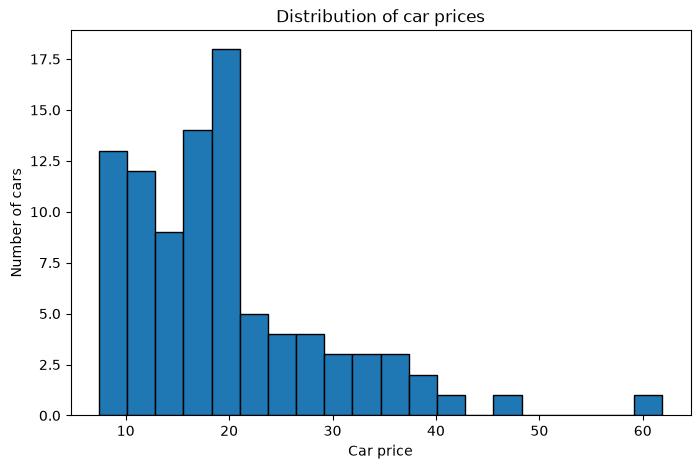

In [18]:
# univariate analysis
# Histogram 

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["Price"],bins = 20, edgecolor="black")
plt.xlabel("Car price")
plt.ylabel("Number of cars")
plt.title("Distribution of car prices")
plt.show()

- Most car prices are between 8 and 22, where the bars are highest.
- Right-skewed distribution: The histogram has a long tail towards higher prices.
- Few expensive cars: Only a few cars have prices above 40.
- Possible outliers: The values near 48 and 62 are far from most observations and should be investigated.

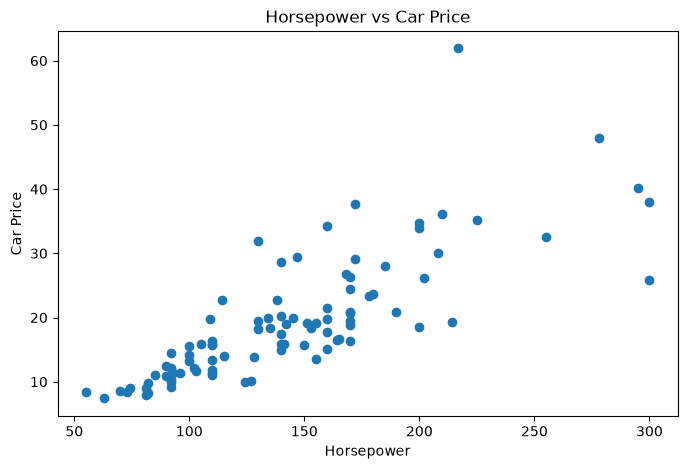

In [20]:
# Bivariate Analysis
# Scatter plot 
plt.figure(figsize=(8, 5))

plt.scatter(df["Horsepower"], df["Price"])

plt.title("Horsepower vs Car Price")
plt.xlabel("Horsepower")
plt.ylabel("Car Price")

plt.show()

- There is a positive relationship between horsepower and car price.
- Cars with higher horsepower generally have higher prices.
- Most cars have horsepower between 80 and 180 and prices between 10 and 25.
- A few cars with higher horsepower have significantly higher prices.

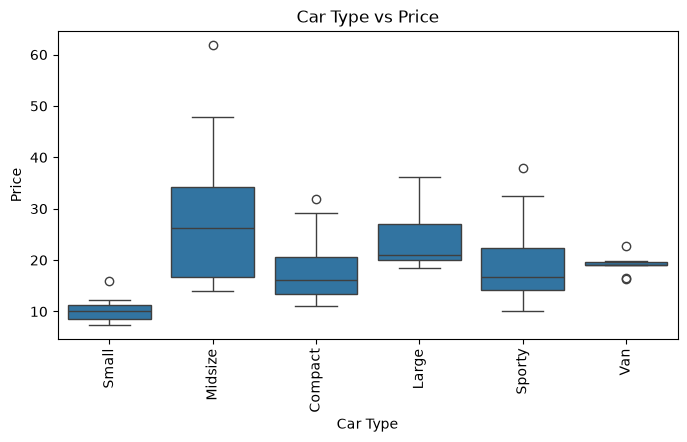

In [64]:
# Boxplot Car type vs Price


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="Type", y="Price")

plt.title("Car Type vs Price")
plt.xlabel("Car Type")
plt.ylabel("Price")

plt.xticks(rotation=90)
plt.show()



- Midsize cars have the highest median price and the widest price variation.
- Small cars generally have lower prices and less variation.
- Compact cars have relatively low prices, with a few outliers.
- Large cars have a median price of around 20–21.
- Sporty cars show considerable price variation, with some expensive outliers.
- Vans have mostly similar prices, with a few outliers.

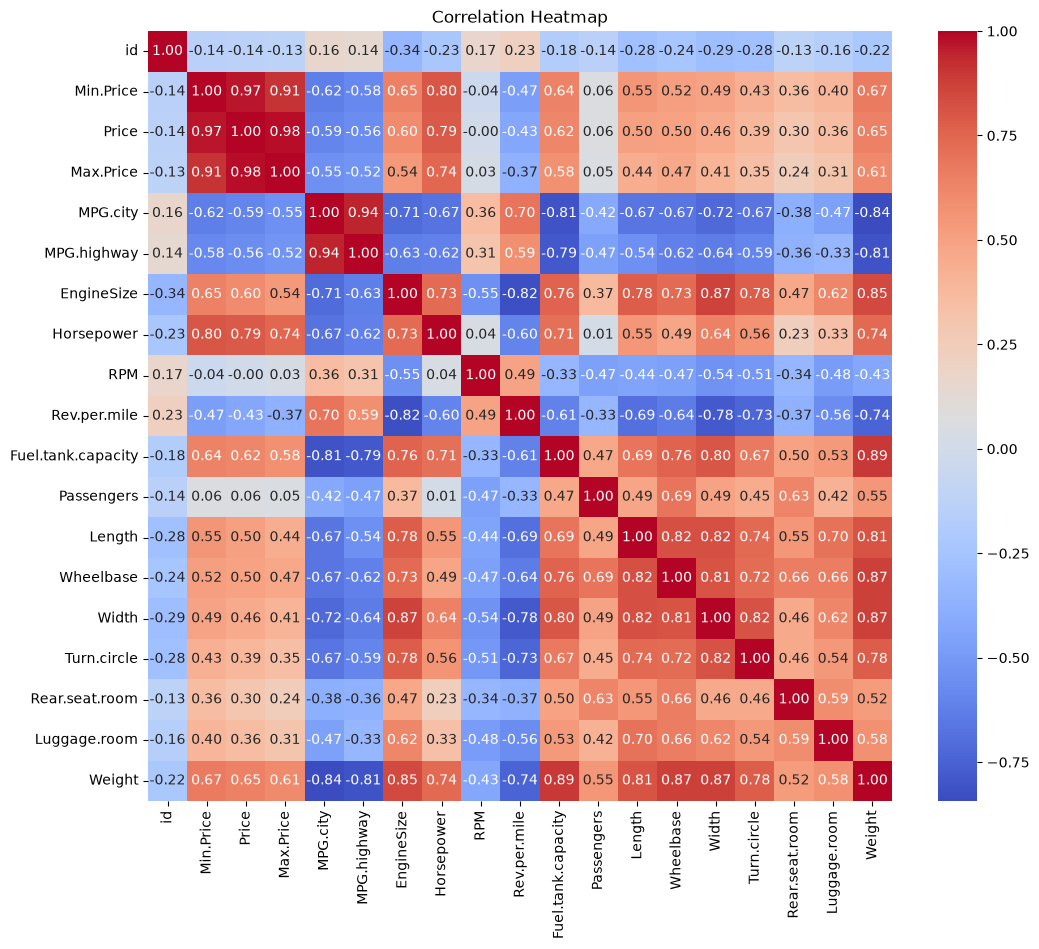

In [32]:
# Correlation Heatmap


import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()


- Min.Price and Price have a strong positive correlation (0.97).
- Price and Max.Price have a strong positive correlation (0.98).
- Weight and Fuel.tank.capacity have a strong positive correlation (0.89).
- MPG.city and Weight have a strong negative correlation (-0.84).
- EngineSize and Width have a strong positive correlation (0.87).
- id has mostly weak correlations with other variables.

###  Step 4: Model Development

In [34]:
# Select Features and target
X = df[["Horsepower", "EngineSize", "Weight",
        "MPG.city", "MPG.highway"]]

y = df["Price"]
print(display(X))
print(display(y))

,Horsepower,EngineSize,Weight,MPG.city,MPG.highway
0,140,1.8,2705,25,31
1,200,3.2,3560,18,25
2,172,2.8,3375,20,26
3,172,2.8,3405,19,26
4,208,3.5,3640,22,30
...,...,...,...,...,...
88,109,2.5,3960,17,21
89,134,2.0,2985,21,30
90,178,2.8,2810,18,25
91,114,2.3,2985,21,28


None


0     15.9
1     33.9
2     29.1
3     37.7
4     30.0
      ... 
88    19.7
89    20.0
90    23.3
91    22.7
92    26.7
Name: Price, Length: 93, dtype: float64

None


### Step 4: Feature Engineering 


In [36]:
# Create numerical pipeline
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

num_pipe = make_pipeline(
    SimpleImputer(strategy='median')
).set_output(transform='pandas')
num_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingne

In [38]:
# Split the data 
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X, y, train_size=0.8, random_state=21
)

In [39]:
print(xtrain.shape,xtest.shape)

(74, 5) (19, 5)


In [40]:
print(ytrain.shape,ytest.shape)

(74,) (19,)


In [ ]:
# Applying pipeline to training and testing data
num_pipe.fit(xtrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Horsepower','EngineSize','Weight','MPG.city','MPG.highway']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, d

In [43]:
xtrain_pre = num_pipe.transform(xtrain)
xtest_pre = num_pipe.transform(xtest)

### Step 5: Model Building

In [44]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(xtrain_pre,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.15,-1.15, 0. , 0.02,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Horsepower','EngineSize','Weight','MPG.city','MPG.highway']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6.439
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


### Check for coefficients(slopes) and yintercept


In [45]:
X.shape[1]

5

In [46]:
X.columns

Index(['Horsepower', 'EngineSize', 'Weight', 'MPG.city', 'MPG.highway'], dtype='str')

In [47]:
model.coef_

array([ 0.15280822, -1.14826704,  0.00255221,  0.01616084, -0.03891449])

In [48]:
model.intercept_

np.float64(-6.438965118243111)

#### Price Prediction

In [49]:
ypred_test = model.predict(xtest_pre)
ypred_test[:5]

array([11.30358439, 20.98760929, 15.20826845, 20.65738213, 23.03918523])

In [50]:
ytest.head()

23    11.3
86    22.7
91    22.7
21    29.5
17    18.8
Name: Price, dtype: float64

### Step 6: Model Evalution: performance Matrix

In [52]:
from sklearn.metrics import mean_squared_error, mean_absolute_error ,r2_score

mse = mean_squared_error(ytest,ypred_test)
mae = mean_absolute_error(ytest,ypred_test)
rmse = mse**0.5
r2 = r2_score(ytest,ypred_test)

print(f"Testing scores")
print(f"MSE:{mse}")
print(f"MAE: {mae}")
print(f"R2 score-Coefficient of Determination:{r2*100:2f}")

Testing scores
MSE:42.41376312187194
MAE: 4.423203244219404
R2 score-Coefficient of Determination:47.355790


### Step 7: Final Deliverables


 The Multiple Linear Regression model achieved an R² score of 47.36%. Since the score is below the expected 80%, the model's performance needs improvement before it can be considered for final deployment.